In [ ]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.preprocessing import image

ROOT_DIR = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
print('TensorFlow version:', tf.__version__)
print('Project Root:', ROOT_DIR.resolve())

TensorFlow version: 2.21.0
Project Root: /Users/bohdan_best/Documents/університет/4 курс/Deep Learning/lab7


In [ ]:
train_dir = ROOT_DIR / 'data' / 'horses-vs-humans' / 'train'
val_dir = ROOT_DIR / 'data' / 'horses-vs-humans' / 'validation'

train_datagen = ImageDataGenerator(rescale=1/255.0)
val_datagen = ImageDataGenerator(rescale=1/255.0)

train_generator = train_datagen.flow_from_directory(
    str(train_dir),
    target_size=(300, 300),
    batch_size=128,
    class_mode='binary'
)

validation_generator = val_datagen.flow_from_directory(
    str(val_dir),
    target_size=(300, 300),
    batch_size=32,
    class_mode='binary'
)

print('Індекси класів:', train_generator.class_indices)

Found 1027 images belonging to 2 classes.
Found 256 images belonging to 2 classes.
Індекси класів: {'horses': 0, 'humans': 1}


Перші 5 імен файлів (коні): ['horse43-5.png', 'horse06-5.png', 'horse20-6.png', 'horse04-7.png', 'horse41-7.png']
Перші 5 імен файлів (люди): ['human17-22.png', 'human10-17.png', 'human10-03.png', 'human07-27.png', 'human09-22.png']
Загальна кількість навчальних фото коней: 500
Загальна кількість навчальних фото людей: 527


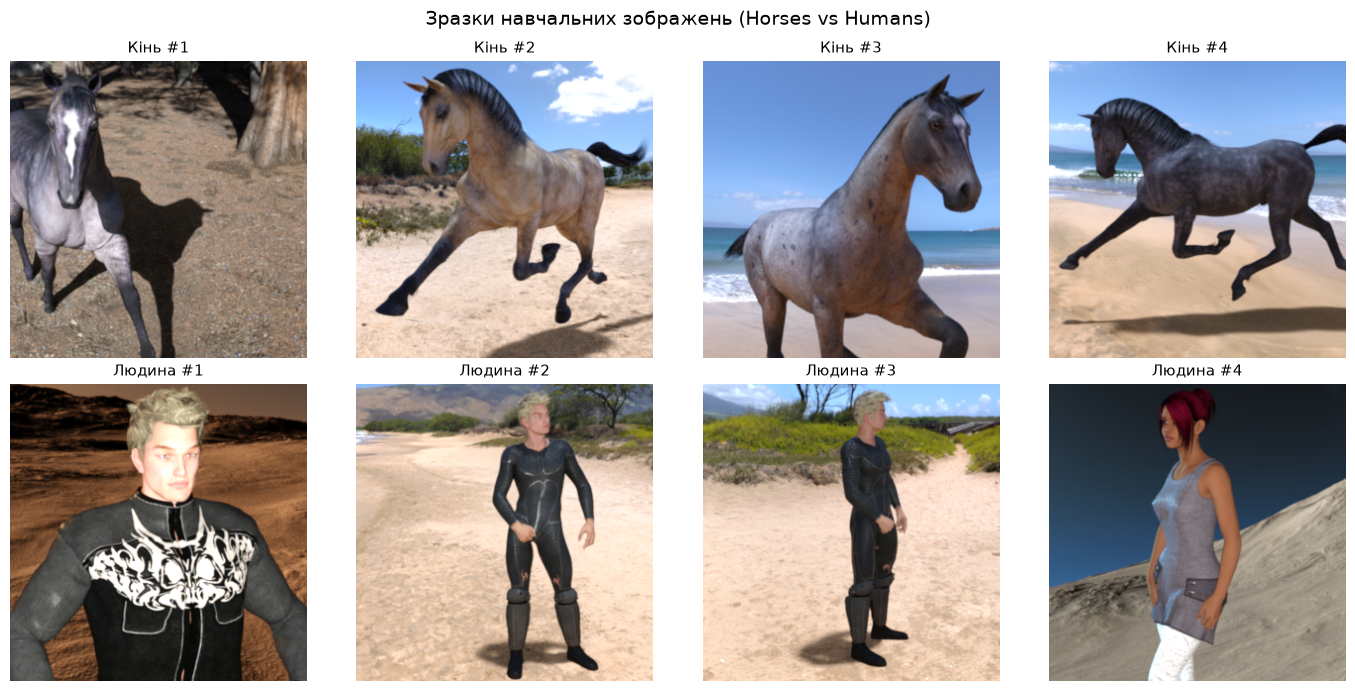

In [ ]:
train_horse_names = os.listdir(train_dir / 'horses')
train_human_names = os.listdir(train_dir / 'humans')

print('Перші 5 імен файлів (коні):', train_horse_names[:5])
print('Перші 5 імен файлів (люди):', train_human_names[:5])
print(f'Загальна кількість навчальних фото коней: {len(train_horse_names)}')
print(f'Загальна кількість навчальних фото людей: {len(train_human_names)}')

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    img_h = Image.open(train_dir / 'horses' / train_horse_names[i])
    axes[0, i].imshow(img_h)
    axes[0, i].set_title(f'Кінь #{i+1}', fontsize=11)
    axes[0, i].axis('off')
    
    img_u = Image.open(train_dir / 'humans' / train_human_names[i])
    axes[1, i].imshow(img_u)
    axes[1, i].set_title(f'Людина #{i+1}', fontsize=11)
    axes[1, i].axis('off')

plt.suptitle('Зразки навчальних зображень (Horses vs Humans)', fontsize=14)
plt.tight_layout()
plt.show()

In [11]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(300, 300, 3)),
    tf.keras.layers.Conv2D(16, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer=RMSprop(learning_rate=0.001),
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 298, 298, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 149, 149, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 147, 147, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 73, 73, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 71, 71, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 35, 35, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 33, 33, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     1,606,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,704,097 (6.50 MB)

 Trainable params: 1,704,097 (6.50 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history = model.fit(
    train_generator,
    steps_per_epoch=8,
    epochs=15,
    validation_data=validation_generator,
    validation_steps=8,
    verbose=1
)

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.5495 - loss: 0.7691 - val_accuracy: 0.5000 - val_loss: 0.6792
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 172ms/step - accuracy: 0.5859 - loss: 0.6573 - val_accuracy: 0.5000 - val_loss: 0.8793
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.5829 - loss: 0.7334 - val_accuracy: 0.5234 - val_loss: 0.6825
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 156ms/step - accuracy: 0.8281 - loss: 0.6543 - val_accuracy: 0.5000 - val_loss: 0.6996
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.6641 - loss: 0.6334 - val_accuracy: 0.7344 - val_loss: 0.5999
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - accuracy: 1.0000 - loss: 0.4942 - val_accuracy: 0.5625 - val_loss: 0.7809
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.7275 - loss: 0.6786 - val_accuracy: 0.8555 - val_loss: 0.5229
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - accuracy: 1.0000 - loss: 0.3141 - val_accuracy: 0.6016 - val_loss: 0.5557


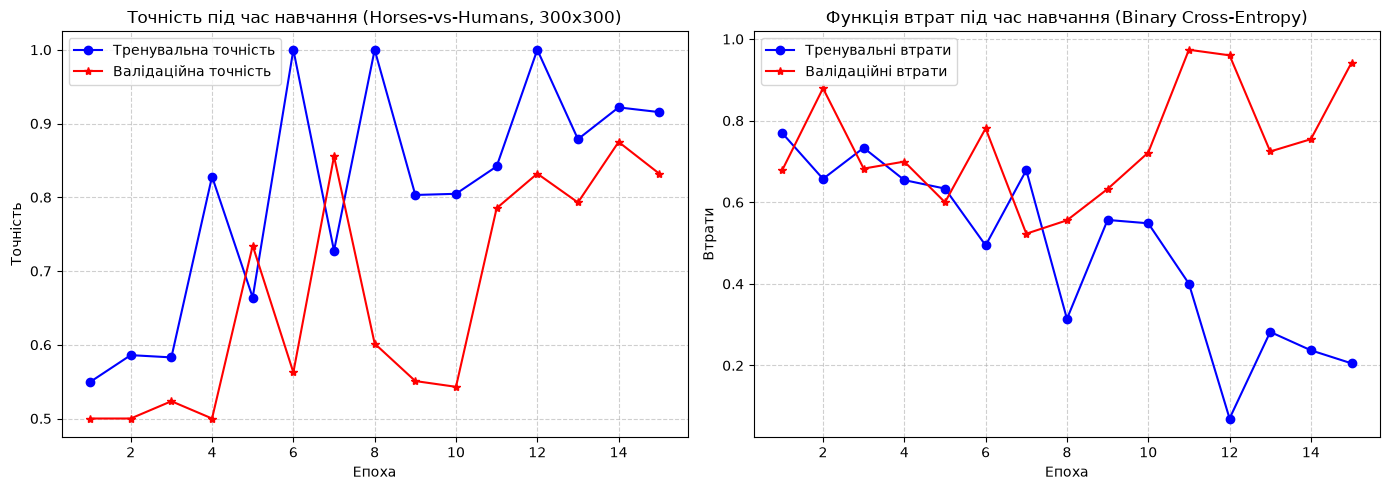

In [13]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'bo-', label='Тренувальна точність')
plt.plot(epochs_range, val_acc, 'r*-', label='Валідаційна точність')
plt.title('Точність під час навчання (Horses-vs-Humans, 300x300)')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'bo-', label='Тренувальні втрати')
plt.plot(epochs_range, val_loss, 'r*-', label='Валідаційні втрати')
plt.title('Функція втрат під час навчання (Binary Cross-Entropy)')
plt.xlabel('Епоха')
plt.ylabel('Втрати')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

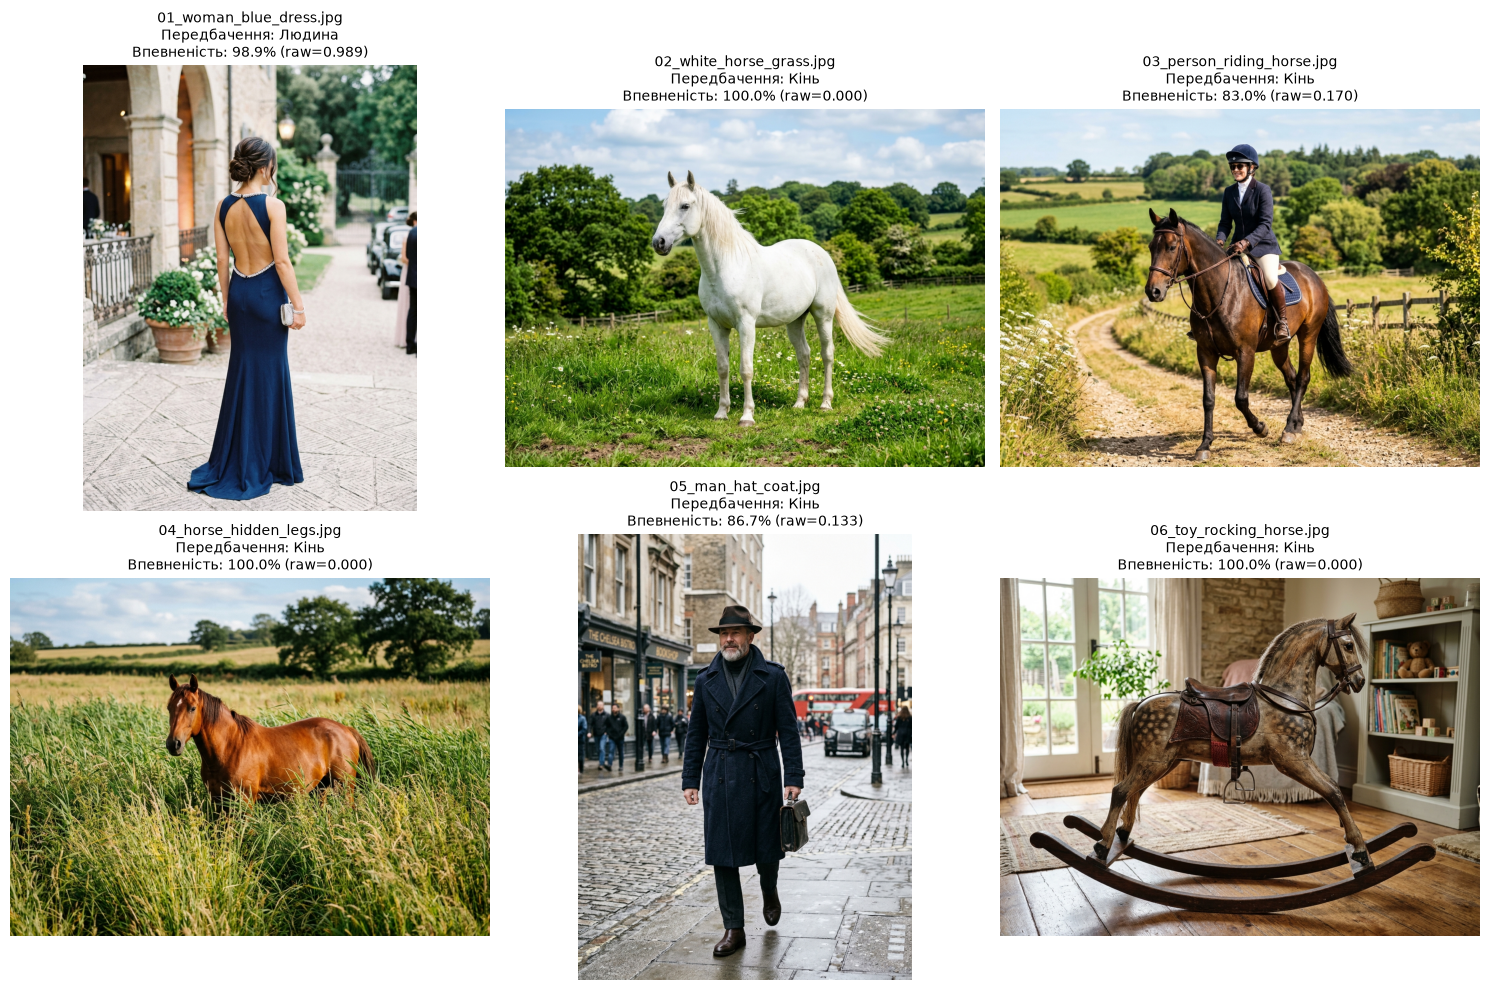

In [ ]:
from pathlib import Path

test_images_dir = ROOT_DIR / 'test_images' / 'horses_humans'
test_files = sorted(list(test_images_dir.glob('*.jpg')))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, img_path in enumerate(test_files):
    img = image.load_img(img_path, target_size=(300, 300))
    x = image.img_to_array(img) / 255.0
    x = np.expand_dims(x, axis=0)
    prob = float(model.predict(x, verbose=0)[0][0])
    
    pred_class = 'Людина' if prob > 0.5 else 'Кінь'
    confidence = prob if prob > 0.5 else (1.0 - prob)
    
    display_img = Image.open(img_path)
    axes[idx].imshow(display_img)
    axes[idx].set_title(f'{img_path.name}\nПередбачення: {pred_class}\nВпевненість: {confidence*100:.1f}% (raw={prob:.3f})',
                        fontsize=10)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()